# Climate Module — NOAA Rainfall Data Exploration

**Author:** Muhammad Kaleem — Climate Module Lead  
**Project:** Plexa — Multi-Modal Smart City Digital Twin and Cascading Resilience Engine  
**Status:** Exploration — finding the right NOAA station before pulling rainfall data

---

## Overview

This notebook is part of the **Climate module** of Plexa, a system designed 
to predict how a hazard in one part of a city — such as a flood — can 
cascade into other interconnected systems, such as traffic congestion.

## Purpose

Identify NOAA weather stations near New York City that record hourly 
rainfall data. This is a prerequisite step before pulling historical 
rainfall data, particularly for **Hurricane Ida (August 28 – September 2, 
2021)**, which serves as the reference event for training a flash-flood 
forecasting model.

## Why Hurricane Ida

Ida caused severe, well-documented flash flooding across NYC and is used 
as the project's benchmark event. The model is trained to learn the 
relationship between rainfall patterns and flooding outcomes by studying 
what occurred during Ida.

## What This Notebook Does

Queries NOAA's public Climate Data Online (CDO) API to list rainfall-
recording stations in the NYC area, in order to select a station with 
reliable, long-term historical coverage (e.g. Central Park).

## Requirements

- A free NOAA CDO API token — [request one here](https://www.ncdc.noaa.gov/cdo-web/token)  
  Used solely for request authentication; not tied to billing or personal data.

> **Note:** The API token is loaded from a local `.env` file and is not 
> included in this notebook or committed to version control.

In [2]:
import requests
from getpass import getpass

# Prompt for token so it isn't saved in the notebook or git history
token = getpass("Enter your NOAA CDO token: ")
headers = {"token": token}

# locationid = New York City (FIPS city code)
# datasetid  = PRECIP_HLY, NOAA's hourly precipitation dataset
params = {
    "locationid": "CITY:US360019",  # New York City
    "datasetid": "PRECIP_HLY",
    "limit": 25
}

response = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/stations",
    headers=headers,
    params=params
)

if response.status_code != 200:
    print(f"Request failed: {response.status_code}")
    print(response.text)
else:
    stations = response.json().get("results", [])
    if not stations:
        print("No stations found.")
    else:
        for s in stations:
            print(f"{s['id']}  —  {s['name']}")

Enter your NOAA CDO token:  ········


COOP:280100  —  ALLENDALE, NJ US
COOP:280907  —  BOONTON 1 SE, NJ US
COOP:282652  —  ELIZABETHPORT, NJ US
COOP:282768  —  ESSEX FELLS SERVICE BUILDING, NJ US
COOP:283572  —  HACKENSACK, NJ US
COOP:284260  —  IRVINGTON, NJ US
COOP:284887  —  LITTLE FALLS, NJ US
COOP:284987  —  LONG BRANCH OAKHURST, NJ US
COOP:286026  —  NEWARK LIBERTY INTERNATIONAL AIRPORT, NJ US
COOP:286146  —  NEW MILFORD, NJ US
COOP:286560  —  ORANGE, NJ US
COOP:287393  —  RAHWAY, NJ US
COOP:287869  —  FORT HANCOCK COAST GUARD STATION, NJ US
COOP:288423  —  SPRINGFIELD, NJ US
COOP:289187  —  WANAQUE RAYMOND DAM, NJ US
COOP:289271  —  WATCHUNG, NJ US
COOP:289455  —  WESTFIELD, NJ US
COOP:289832  —  WOODCLIFF LAKE, NJ US
COOP:302129  —  DOBBS FERRY ARDSLEY, NY US
COOP:304613  —  LARCHMONT, NY US
COOP:305377  —  MINEOLA, NY US
COOP:305382  —  MINEOLA 1 W, NY US
COOP:305403  —  HEMPSTEAD MITCHELL FIELD AFB, NY US
COOP:305796  —  NEW YORK, NY US
COOP:305799  —  NEW YORK BOTANICAL GARDEN, NY US


## Narrowing the search to Manhattan

The initial NYC metro-wide search didn't surface a Central Park station 
within the first 25 results. Narrowing to New York County (Manhattan) 
specifically to find it.

In [3]:
import requests
from getpass import getpass

token = getpass("Enter your NOAA CDO token: ")
headers = {"token": token}

# FIPS:36061 = New York County (Manhattan) — narrower than the metro-wide city code
params = {
    "locationid": "FIPS:36061",
    "datasetid": "PRECIP_HLY",
    "limit": 50
}

response = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/stations",
    headers=headers,
    params=params
)

if response.status_code != 200:
    print(f"Request failed: {response.status_code}")
    print(response.text)
else:
    stations = response.json().get("results", [])
    if not stations:
        print("No stations found.")
    else:
        for s in stations:
            print(f"{s['id']}  —  {s['name']}")

Enter your NOAA CDO token:  ········


COOP:305801  —  NY CITY CENTRAL PARK, NY US
COOP:305816  —  WORLD TRADE CENTER, NY US


## Station Selected

**Station ID:** `COOP:305801`  
**Name:** NY City Central Park, NY US  
**Reason:** Long historical coverage, standard reference station for NYC 
weather/climate research.

## Pulling Hourly Precipitation — Ida Window (Aug 28 – Sep 2, 2021)

Station: NY City Central Park (`COOP:305801`)

In [6]:
import pandas as pd
import requests
from getpass import getpass
# Same token prompt as before — kept separate per cell so this section
# can be re-run independently later
token = getpass("Enter your NOAA CDO token: ")
headers = {"token": token}

params = {
    "datasetid": "PRECIP_HLY",
    "stationid": "COOP:305801",       # NY City Central Park
    "startdate": "2021-08-28",
    "enddate": "2021-09-02",
    "units": "metric",
    "limit": 1000
}

response = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/data",
    headers=headers,
    params=params
)

if response.status_code != 200:
    print(f"Request failed: {response.status_code}")
    print(response.text)
else:
    records = response.json().get("results", [])
    if not records:
        print("No data returned — check date range or station ID.")
    else:
        df = pd.DataFrame(records)
        print(f"Pulled {len(df)} records")
        display(df.head())

Enter your NOAA CDO token:  ········


No data returned — check date range or station ID.


In [7]:
print(response.status_code)
print(response.json())

200
{}


In [8]:
station_check = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/stations/COOP:305801",
    headers=headers
)
print(station_check.json())

{'elevation': 42.7, 'mindate': '1944-04-01', 'maxdate': '2015-11-01', 'latitude': 40.77898, 'name': 'NY CITY CENTRAL PARK, NY US', 'datacoverage': 0.9988, 'id': 'COOP:305801', 'elevationUnit': 'METERS', 'longitude': -73.96925}


In [9]:
params = {
    "datasetid": "GHCND",
    "locationid": "FIPS:36061",   # New York County (Manhattan)
    "limit": 50
}

response = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/stations",
    headers=headers,
    params=params
)

stations = response.json().get("results", [])
for s in stations:
    print(s["id"], "—", s["name"], "—", s["mindate"], "to", s["maxdate"])

GHCND:US1NYNY0074 — NEW YORK 8.8 N, NY US — 2018-07-13 to 2021-11-22
GHCND:US1NYNY0078 — STUYVESANT SQUARE PARK NEW YORK 4.9 NNW, NY US — 2019-08-26 to 2020-05-05
GHCND:US1NYNY0082 — MATTHEWS PALMER PLAYGROUND NEW YORK 6.8 NNW, NY US — 2020-11-16 to 2021-10-19
GHCND:USC00305816 — WORLD TRADE CENTER, NY US — 1871-01-01 to 2024-06-17
GHCND:USC00309580 — WORLD TRADE CENTER, NY US — 2022-02-01 to 2023-07-07
GHCND:USW00094728 — NY CITY CENTRAL PARK, NY US — 1869-01-01 to 2026-09-22


## Correction: Switching to GHCND Dataset

The original station (`COOP:305801`) stopped reporting in Nov 2015 — 
before Ida occurred, so it has no usable data for this project.

**New station:** `GHCND:USW00094728` — NY City Central Park  
**Dataset:** GHCND (Global Historical Climatology Network - Daily)  
**Coverage:** 1869–2026, confirmed to include the Ida window (Aug 28 – Sep 2, 2021)

Note: GHCND is daily-resolution, not hourly. We'll use daily precipitation 
totals for now; if hourly detail is needed later, a separate NWS/ASOS 
source will need to be explored.

In [10]:
params = {
    "datasetid": "GHCND",
    "stationid": "GHCND:USW00094728",
    "datatypeid": "PRCP",          # precipitation
    "startdate": "2021-08-28",
    "enddate": "2021-09-02",
    "units": "metric",
    "limit": 1000
}

response = requests.get(
    "https://www.ncdc.noaa.gov/cdo-web/api/v2/data",
    headers=headers,
    params=params
)

print(response.status_code)
records = response.json().get("results", [])

if not records:
    print("No data returned.")
else:
    df = pd.DataFrame(records)
    print(f"Pulled {len(df)} records")
    display(df)

200
Pulled 6 records


,date,datatype,station,attributes,value
0,2021-08-28T00:00:00,PRCP,GHCND:USW00094728,"T,,W,2400",0.0
1,2021-08-29T00:00:00,PRCP,GHCND:USW00094728,",,W,2400",0.0
2,2021-08-30T00:00:00,PRCP,GHCND:USW00094728,"T,,W,2400",0.0
3,2021-08-31T00:00:00,PRCP,GHCND:USW00094728,",,W,2400",0.0
4,2021-09-01T00:00:00,PRCP,GHCND:USW00094728,",,W,2400",181.1
5,2021-09-02T00:00:00,PRCP,GHCND:USW00094728,",,W,2400",2.5


In [11]:
import os

os.makedirs("data/raw", exist_ok=True)
df.to_csv("data/raw/noaa_precip_ida.csv", index=False)
print("Saved to data/raw/noaa_precip_ida.csv")

Saved to data/raw/noaa_precip_ida.csv


## Pulling NYC 311 Flood Complaints — Ida Window (Aug 28 – Sep 2, 2021)

Purpose: Get ground-truth data on where/when flooding was actually 
reported, to compare against the rainfall data pulled above.

In [12]:
import requests
import pandas as pd

# NYC Open Data — 311 Service Requests dataset
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

params = {
    "$where": "created_date between '2021-08-28T00:00:00' and '2021-09-03T00:00:00' "
               "AND complaint_type like '%Flood%'",
    "$limit": 5000
}

response = requests.get(url, params=params)
print(response.status_code)

records = response.json()
df_311 = pd.DataFrame(records)
print(f"Pulled {len(df_311)} records")
display(df_311.head())

200
Pulled 0 records


""


In [13]:
params = {
    "$where": "created_date between '2021-08-28T00:00:00' and '2021-09-03T00:00:00'",
    "$select": "complaint_type, count(*) as total",
    "$group": "complaint_type",
    "$order": "total DESC",
    "$limit": 50
}

response = requests.get(url, params=params)
print(response.status_code)

df_types = pd.DataFrame(response.json())
display(df_types)

200


,complaint_type,total
0,Request Large Bulky Item Collection,6411
1,Noise - Residential,5621
2,Sewer,5208
3,Illegal Parking,4939
4,Noise - Street/Sidewalk,4072
5,Blocked Driveway,2506
6,UNSANITARY CONDITION,2259
7,WATER LEAK,2164
8,Noise - Vehicle,1670
9,PAINT/PLASTER,1498


In [14]:
params = {
    "$where": "created_date between '2021-08-28T00:00:00' and '2021-09-03T00:00:00' "
               "AND complaint_type = 'Sewer'",
    "$limit": 5000
}

response = requests.get(url, params=params)
print(response.status_code)

df_311 = pd.DataFrame(response.json())
print(f"Pulled {len(df_311)} records")
display(df_311.head())

200
Pulled 5000 records


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,incident_zip,incident_address,...,x_coordinate_state_plane,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,latitude,longitude,location,intersection_street_1,intersection_street_2
0,51726662,2021-09-01T11:51:00.000,2022-06-06T10:50:00.000,DEP,Department of Environmental Protection,Sewer,Defective/Missing Curb Piece (SC4),SC4,11223,158 AVENUE U,...,990262,156563,PHONE,Unspecified,BROOKLYN,40.59640346721013,-73.97835164996047,"{'type': 'Point', 'coordinates': [-73.97835164...",NaN,NaN
1,51722533,2021-09-02T08:57:00.000,2021-09-06T11:45:00.000,DEP,Department of Environmental Protection,Sewer,Sewer Backup (Use Comments) (SA),SA,NaN,ARTHUR KILL,...,NaN,NaN,ONLINE,Unspecified,Unspecified,NaN,NaN,NaN,NaN,NaN
2,51720823,2021-09-02T11:39:00.000,2021-09-04T12:05:00.000,DEP,Department of Environmental Protection,Sewer,Sewer Backup (Use Comments) (SA),SA,11375,61-20 GRAND CENTRAL PARKWAY SR WEST,...,1026714,208337,ONLINE,Unspecified,QUEENS,40.73841162977033,-73.84676725605964,"{'type': 'Point', 'coordinates': [-73.84676725...",NaN,NaN
3,51716268,2021-09-02T17:29:00.000,2021-09-02T23:05:00.000,DEP,Department of Environmental Protection,Sewer,Sewer Backup (Use Comments) (SA),SA,10304,505 WESER AVENUE,...,960476,160030,ONLINE,Unspecified,STATEN ISLAND,40.605889827157306,-74.08561894215285,"{'type': 'Point', 'coordinates': [-74.08561894...",NaN,NaN
4,51718375,2021-09-02T20:12:00.000,2021-09-07T21:45:00.000,DEP,Department of Environmental Protection,Sewer,Sewer Backup (Use Comments) (SA),SA,10465,853 QUINCY AVENUE,...,1032116,240823,ONLINE,Unspecified,BRONX,40.82754929715136,-73.82704254907786,"{'type': 'Point', 'coordinates': [-73.82704254...",NaN,NaN


In [15]:
params_count = {
    "$where": "created_date between '2021-08-28T00:00:00' and '2021-09-03T00:00:00' "
               "AND complaint_type = 'Sewer'",
    "$select": "count(*) as total"
}

response = requests.get(url, params=params_count)
print(response.json())

[{'total': '5208'}]


In [16]:
all_records = []
offset = 0
batch_size = 1000

while True:
    params = {
        "$where": "created_date between '2021-08-28T00:00:00' and '2021-09-03T00:00:00' "
                   "AND complaint_type = 'Sewer'",
        "$limit": batch_size,
        "$offset": offset
    }
    response = requests.get(url, params=params)
    batch = response.json()

    if not batch:
        break

    all_records.extend(batch)
    offset += batch_size

df_311 = pd.DataFrame(all_records)
print(f"Pulled {len(df_311)} total records")

Pulled 5208 total records


In [17]:
os.makedirs("data/raw", exist_ok=True)
df_311.to_csv("data/raw/nyc311_sewer_ida.csv", index=False)
print("Saved to data/raw/nyc311_sewer_ida.csv")

Saved to data/raw/nyc311_sewer_ida.csv


In [18]:
df_311["created_date"] = pd.to_datetime(df_311["created_date"])
daily_complaints = df_311.groupby(df_311["created_date"].dt.date).size()
print(daily_complaints)

created_date
2021-08-28      71
2021-08-29      56
2021-08-30     112
2021-08-31     117
2021-09-01    1657
2021-09-02    3195
dtype: int64


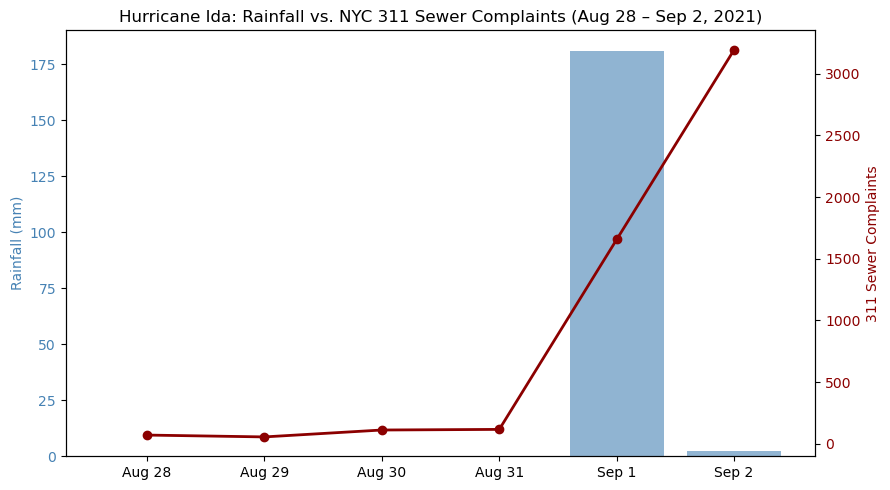

In [19]:
import matplotlib.pyplot as plt

dates = ["Aug 28", "Aug 29", "Aug 30", "Aug 31", "Sep 1", "Sep 2"]
rainfall = [0.0, 0.0, 0.0, 0.0, 181.1, 2.5]
complaints = [71, 56, 112, 117, 1657, 3195]

fig, ax1 = plt.subplots(figsize=(9, 5))

# Rainfall as bars on the left axis
ax1.bar(dates, rainfall, color="steelblue", alpha=0.6, label="Rainfall (mm)")
ax1.set_ylabel("Rainfall (mm)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

# Complaints as a line on a second axis (different scale)
ax2 = ax1.twinx()
ax2.plot(dates, complaints, color="darkred", marker="o", linewidth=2, label="Sewer Complaints")
ax2.set_ylabel("311 Sewer Complaints", color="darkred")
ax2.tick_params(axis="y", labelcolor="darkred")

plt.title("Hurricane Ida: Rainfall vs. NYC 311 Sewer Complaints (Aug 28 – Sep 2, 2021)")
fig.tight_layout()
plt.show()

## Key Finding: Rainfall–Complaint Correlation Confirmed

Sewer complaint volume rose sharply on the same day as peak rainfall 
(Sep 1) and remained elevated the following day (Sep 2), even as 
rainfall dropped. This suggests flood-related reporting lags 1 day 
behind peak rainfall — likely due to cumulative water buildup and 
delayed damage reporting.

**Implication for modeling:** the Climate module should consider rainfall 
over a rolling window (e.g. past 24–48 hours), not just same-day rainfall, 
when predicting flood risk.

In [21]:
os.makedirs("data/processed", exist_ok=True)

summary = pd.DataFrame({
    "date": dates,
    "rainfall_mm": rainfall,
    "sewer_complaints": complaints
})
summary.to_csv("data/processed/ida_daily_summary.csv", index=False)
print("Saved processed summary")

Saved processed summary
